## CLASIFICACIÓN BINARIA CON OXFORD_IIIT_PET

In [ ]:
import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt


In [ ]:
#!pip install tensorflow_datasets
#!pip install importlib-resources

In [ ]:
ds = tfds.load("oxford_iiit_pet")

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/oxford_iiit_pet/incomplete.84J9G8_4.0.0/oxford_iiit_pet-train.tfrecord-[0-…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/oxford_iiit_pet/incomplete.84J9G8_4.0.0/oxford_iiit_pet-test.tfrecord-[0-9…

Dataset oxford_iiit_pet downloaded and prepared to /root/tensorflow_datasets/oxford_iiit_pet/4.0.0. Subsequent calls will reuse this data.


In [ ]:
NOMBRES = ["",""]

In [ ]:
def procesar(d):
  img = tf.image.resize(d["image"], (128,128))/255
  return img, d["species"]

In [ ]:
train = ds["train"].map(procesar).shuffle(1000).batch(32)
test = ds["test"].map(procesar).shuffle(1000).batch(32)

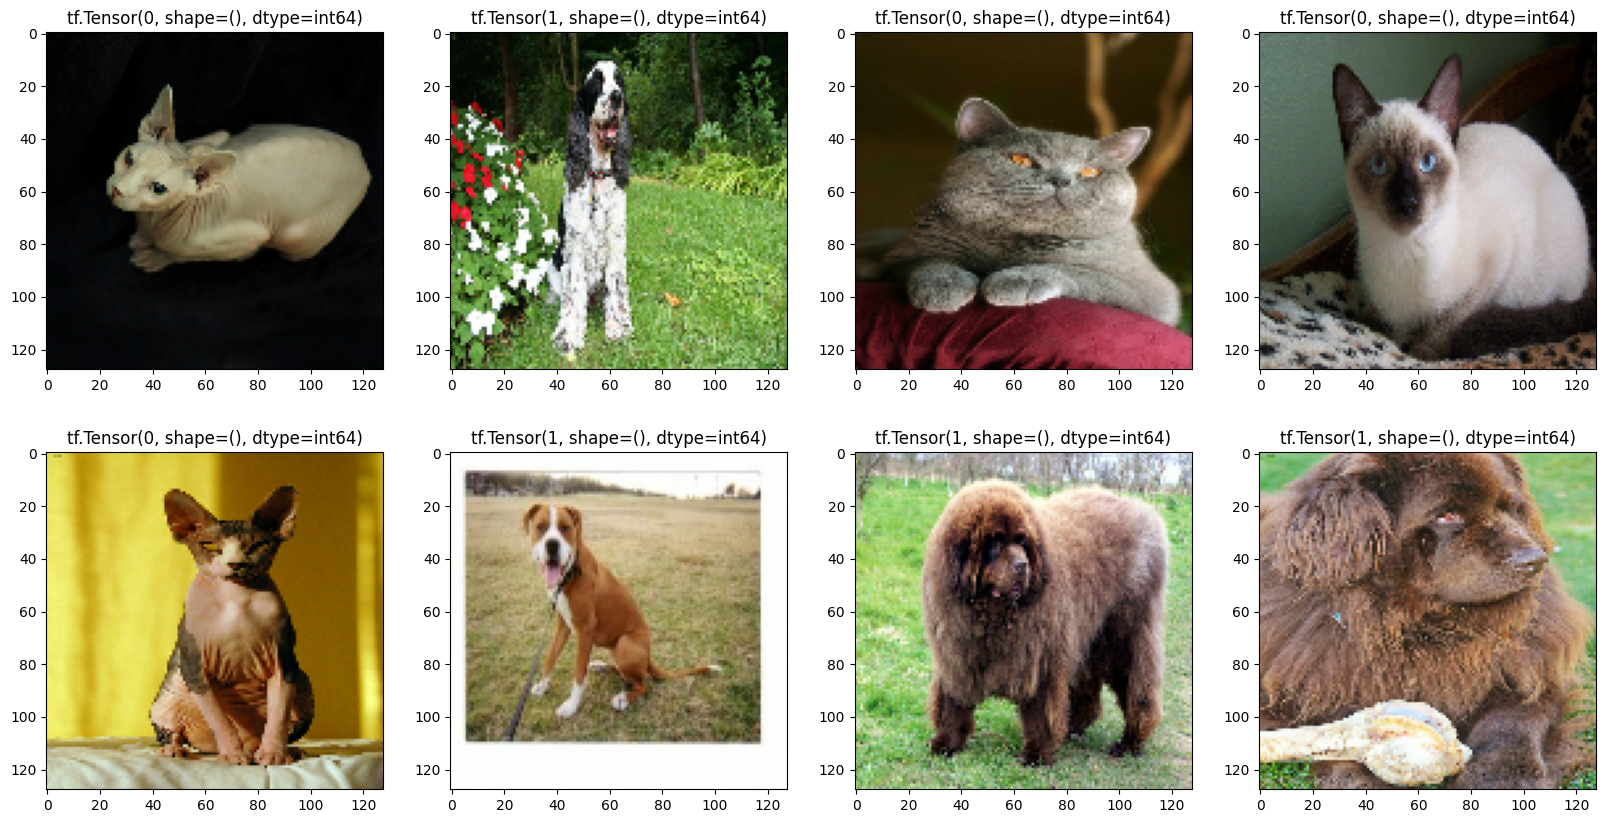

In [ ]:
plt. figure(figsize=(20,10))
for i, (img,y) in enumerate(ds["train"].map(procesar).take(8)):
  plt.subplot(2,4,i+1)
  plt.imshow(img)
  plt.title(y)

In [ ]:
model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(128,128,3)),
    tf.keras.layers.Conv2D(16,3,activation="relu"), #EXTRAE EL MAPA DE CARACTERÍSTICAS
    tf.keras.layers.MaxPooling2D(), #Reduce la dimensionalidad del mapa de características
    tf.keras.layers.Conv2D(32,3,activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(64,3,activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Flatten(), #APLANAMOS PARA ENVIAR A CAPA DENSA
    tf.keras.layers.Dense(64,activation="relu"),
    tf.keras.layers.Dense(1,activation="sigmoid") #PREPARAMOS SALIDA BINARIA
])
model.compile(optimizer="adam",loss="binary_crossentropy",metrics=["accuracy"])

In [ ]:
model.fit(train, epochs=5, validation_data = test)

Epoch 1/5
115/115 ━━━━━━━━━━━━━━━━━━━━ 24s 133ms/step - accuracy: 0.6802 - loss: 0.6064 - val_accuracy: 0.6887 - val_loss: 0.5544
Epoch 2/5
115/115 ━━━━━━━━━━━━━━━━━━━━ 15s 117ms/step - accuracy: 0.7209 - loss: 0.5459 - val_accuracy: 0.7348 - val_loss: 0.5451
Epoch 3/5
115/115 ━━━━━━━━━━━━━━━━━━━━ 16s 119ms/step - accuracy: 0.7549 - loss: 0.4966 - val_accuracy: 0.7653 - val_loss: 0.4825
Epoch 4/5
115/115 ━━━━━━━━━━━━━━━━━━━━ 15s 118ms/step - accuracy: 0.8024 - loss: 0.4283 - val_accuracy: 0.7544 - val_loss: 0.5264
Epoch 5/5
115/115 ━━━━━━━━━━━━━━━━━━━━ 16s 119ms/step - accuracy: 0.8315 - loss: 0.3806 - val_accuracy: 0.7618 - val_loss: 0.5010


In [ ]:
imgs, etiquetas = next(iter(test))
probs = model.predict(imgs[:8]).flatten()
print("Etiquetas reales: \n", etiquetas[:8])
print("Predicciones: \n", probs.round().astype(int))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
Etiquetas reales: 
 tf.Tensor([1 1 0 1 0 0 1 1], shape=(8,), dtype=int64)
Predicciones: 
 [1 1 0 1 1 1 1 1]


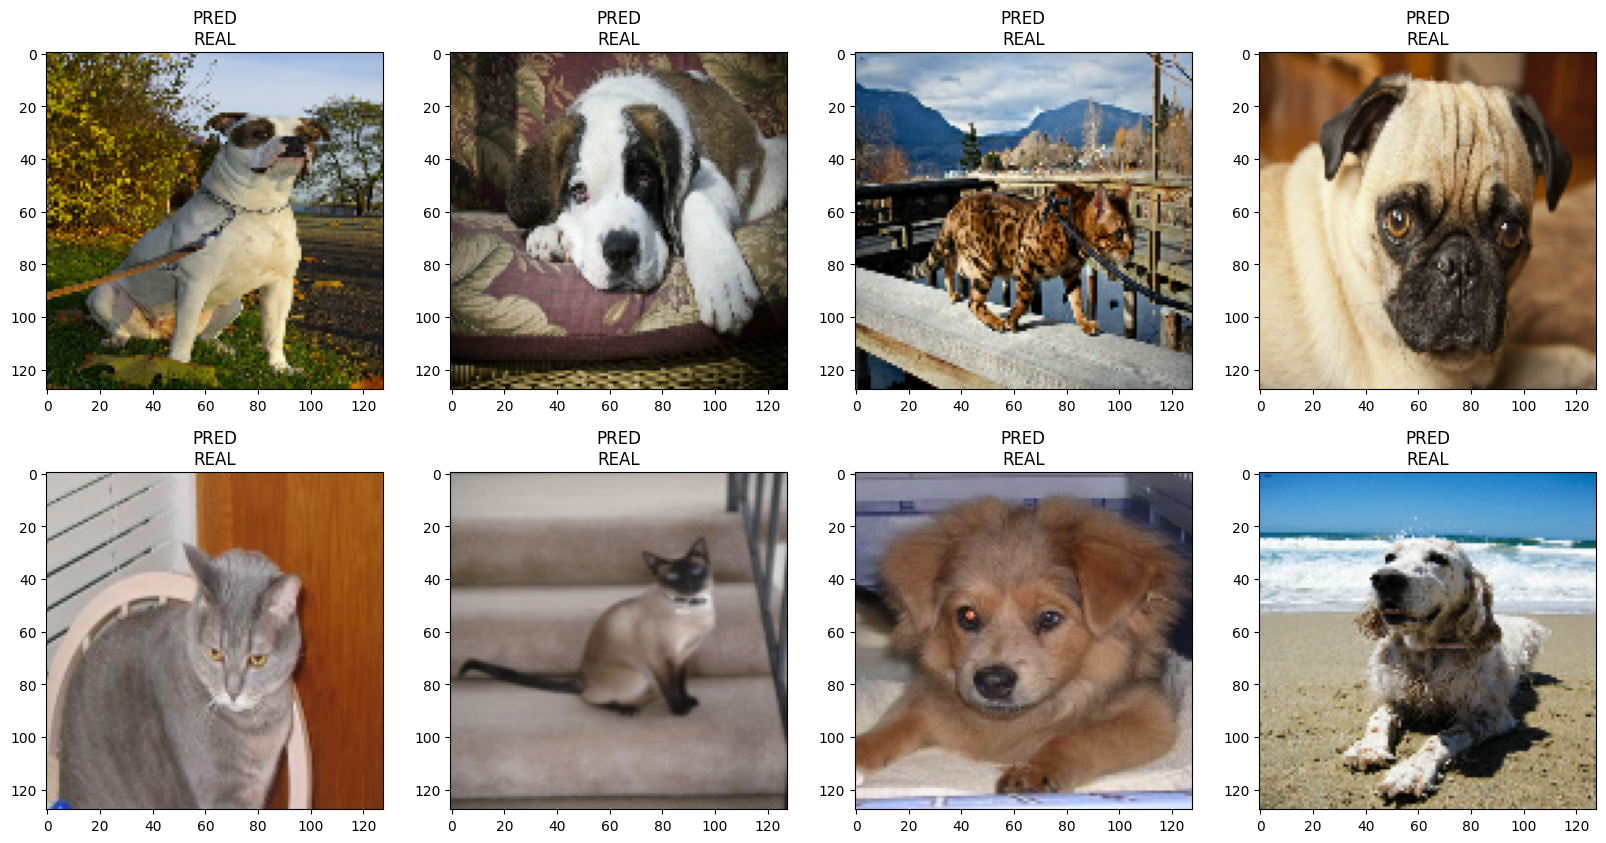

In [ ]:
plt.figure(figsize=(20,10))
for i in range(8):
  plt.subplot(2,4,i+1)
  plt.imshow(imgs[i])
  plt.title("PRED" + str(NOMBRES[probs.round().astype(int)[i]])+"\nREAL" + str(NOMBRES[etiquetas[i]]))